In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

#CARGAR DATASET DESDE GITHUB RAW
url = "https://raw.githubusercontent.com/microcrafted/DatasetOnlineshoppers/main/online_shoppers_intention.csv"
df = pd.read_csv(url)

#GUARDAR COPIA DE RESPALDO ORIGINAL
df_original = df.copy()

#INSPECCIONAR DIMENSIONES Y TIPOS DE DATOS
print("Dimensiones iniciales:", df.shape)
df.info()
df.head()

Dimensiones iniciales: (12330, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


# NOTA 1:
#### - Cargamos las 12330 sesiones y las 18 columnas desde el repo de Axel y protegemos el dataframe original haciendo una copia
#### - Permitimos ver diferentes tipos de datos y comprobamos desde el inicio que OperatingSystems, Browser, Region y TrafficType son variables categoricas nominales aunque sean enteros

In [72]:
#CLASIFICAR VARIABLES SEGUN SU NATURALEZA REAL
variables_numericas = [
    'Administrative', 'Administrative_Duration',
    'Informational', 'Informational_Duration',
    'ProductRelated', 'ProductRelated_Duration',
    'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay'
]

variables_nominales_codigo = ['OperatingSystems', 'Browser', 'Region', 'TrafficType']
variables_categoricas = ['Month', 'VisitorType', 'Weekend', 'Revenue'] + variables_nominales_codigo

#REVISAR VALORES FALTANTES
faltantes = pd.DataFrame({
    'Cantidad': df.isna().sum(),
    'Porcentaje': (df.isna().mean() * 100).round(2)
})
print("TOTAL DE NULOS:", df.isna().sum().sum())
display(faltantes)

#VER REGISTROS DUPLICADOS ANTES DE ELIMINARLOS
duplicados_mask = df.duplicated(keep='first')
df_duplicados = df[duplicados_mask]

print("REGISTROS DUPLICADOS EXACTOS:", duplicados_mask.sum())
print("REVENUE EN DUPLICADOS:")
print(df_duplicados['Revenue'].value_counts())
print("DUPLICADOS CON PRODUCTRELATED_DURATION = 0:", (df_duplicados['ProductRelated_Duration'] == 0).sum())
print("DUPLICADOS CON BOUNCERATES = 0.20:", (df_duplicados['BounceRates'] == 0.20).sum())

#ELIMINAR REGISTROS DUPLICADOS Y REINICIAR INDICE
renglones_antes = len(df)
df = df.drop_duplicates(keep='first').reset_index(drop=True)
renglones_despues = len(df)

print("Renglones antes:", renglones_antes)
print("Renglones despues:", renglones_despues)
print("Duplicados eliminados:", renglones_antes - renglones_despues)

TOTAL DE NULOS: 0


,Cantidad,Porcentaje
Administrative,0,0.0
Administrative_Duration,0,0.0
Informational,0,0.0
Informational_Duration,0,0.0
ProductRelated,0,0.0
ProductRelated_Duration,0,0.0
BounceRates,0,0.0
ExitRates,0,0.0
PageValues,0,0.0
SpecialDay,0,0.0


REGISTROS DUPLICADOS EXACTOS: 125
REVENUE EN DUPLICADOS:
Revenue
False    125
Name: count, dtype: int64
DUPLICADOS CON PRODUCTRELATED_DURATION = 0: 125
DUPLICADOS CON BOUNCERATES = 0.20: 125
Renglones antes: 12330
Renglones despues: 12205
Duplicados eliminados: 125


# NOTA 2:
#### VERIFICAMOS QUE HAY CERO NULOS Y VEMOS QUE HAY 125 DUPLICADOS PARA DESPUES BORRARLOS Y DEJAR EL DATASET EN 12205 FILAS TOTALMENTE LIMPIAS
#### LOS 125 DUPLICADOS SON SESIONES CON REVENUE = FALSE, CON DURACION 0 Y REBOTE MAXIMO 0,20, ASI QUE LO IDENTIFICAMOS COMO TRAFICO REPETITIVO CON REBOTE INSTANTANEO

In [73]:
#DEFINIR UMBRALES
umbrales = {
    'Administrative': {'min': 0, 'max': 1000},
    'Administrative_Duration': {'min': 0, 'max': 86400},
    'Informational': {'min': 0, 'max': 1000},
    'Informational_Duration': {'min': 0, 'max': 86400},
    'ProductRelated': {'min': 0, 'max': 1000},
    'ProductRelated_Duration': {'min': 0, 'max': 86400},
    'BounceRates': {'min': 0.0, 'max': 0.2},
    'ExitRates': {'min': 0.0, 'max': 0.2},
    'PageValues': {'min': 0.0, 'max': 1000.0},
    'SpecialDay': {'min': 0.0, 'max': 1.0}
}

#VERIFICAR VALORES FUERA DE RANGO LOGICO
reglas_invalidas = {
    v: ~df[v].between(lim['min'], lim['max'])
    for v, lim in umbrales.items()
}

for v, mascara in reglas_invalidas.items():
    print(f"Fuera de rango en {v}: {mascara.sum()}")

#REVISAR CONSISTENCIA CRUZADA ENTRE PAGINAS Y DURACION
pares_consistencia = [
    ('Administrative', 'Administrative_Duration'),
    ('Informational', 'Informational_Duration'),
    ('ProductRelated', 'ProductRelated_Duration')
]

for pag, dur in pares_consistencia:
    imposible = ((df[pag] == 0) & (df[dur] > 0)).sum()
    rebote_cero_seg = ((df[pag] > 0) & (df[dur] == 0)).sum()
    print(f"{pag}=0 y {dur}>0 (imposible): {imposible} | {pag}>0 y {dur}=0 (rebote): {rebote_cero_seg}")

#REVISAR SESIONES SIN PAGINAS Y CASOS BOUNCE MAYOR A EXIT
sin_paginas = ((df['Administrative'] + df['Informational'] + df['ProductRelated']) == 0).sum()
bounce_mayor_exit = (df['BounceRates'] > df['ExitRates']).sum()
print("Sesiones con 0 paginas totales:", sin_paginas)
print("Sesiones con BounceRates > ExitRates:", bounce_mayor_exit)

#CONVERTIR CODIGOS NOMINALES Y TEXTO A TIPO CATEGORY
for col in variables_nominales_codigo + ['Month', 'VisitorType']:
    df[col] = df[col].astype('category')

df.info()

Fuera de rango en Administrative: 0
Fuera de rango en Administrative_Duration: 0
Fuera de rango en Informational: 0
Fuera de rango en Informational_Duration: 0
Fuera de rango en ProductRelated: 0
Fuera de rango en ProductRelated_Duration: 0
Fuera de rango en BounceRates: 0
Fuera de rango en ExitRates: 0
Fuera de rango en PageValues: 0
Fuera de rango en SpecialDay: 0
Administrative=0 y Administrative_Duration>0 (imposible): 0 | Administrative>0 y Administrative_Duration=0 (rebote): 135
Informational=0 y Informational_Duration>0 (imposible): 0 | Informational>0 y Informational_Duration=0 (rebote): 226
ProductRelated=0 y ProductRelated_Duration>0 (imposible): 0 | ProductRelated>0 y ProductRelated_Duration=0 (rebote): 592
Sesiones con 0 paginas totales: 6
Sesiones con BounceRates > ExitRates: 175
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12205 entries, 0 to 12204
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --

# NOTA 3:
#### - DEFINIMOS LOS UMBRALES, VERIFICAMOS VALORES FUERA DE RANGO Y VERIFICAMOSS LA CONSISTENCIA ENTRE LAS PAGINAS Y SU DURACION
#### - CONVERTIMOS A CATEGOORY LAS COLUMNAS QUE SON VARIABLES CATEGORICAS Y SE PUEDEN CONFUNDIR CON ENTEROS
#### - EVITAMOS QUE DESCRIBE() O CUALQUIER OTRA COSA TRATE LAS VARIBABLES CATEGORICAS COMO VARIABLES NUMERICAS

In [74]:
#FUNCION PARA DETECTAR OUTLIERS/ATIPICOS MEDIANTE RANGO INTERCUARTILICO
def detectar_outliers_iqr(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    mascara = (serie < limite_inferior) | (serie > limite_superior)
    return mascara, limite_inferior, limite_superior

#CONSTRUIR TABLA DE CUARTILES Y CONTEO DE ATIPICOS
resumen_outliers = []

for v in variables_numericas:
    mascara, li, ls = detectar_outliers_iqr(df[v])
    resumen_outliers.append({
        'Variable': v,
        'Q1_25%': round(df[v].quantile(0.25), 3),
        'Mediana_50%': round(df[v].quantile(0.50), 3),
        'Q3_75%': round(df[v].quantile(0.75), 3),
        'Lim_Inf_IQR': round(li, 3),
        'Lim_Sup_IQR': round(ls, 3),
        'Outliers': int(mascara.sum()),
        'Porcentaje_%': round(mascara.mean() * 100, 2)
    })

df_outliers = pd.DataFrame(resumen_outliers)
display(df_outliers)

#COMPROBAR POR QUE NO SE DEBEN ELIMINAR OUTLIERS DE PAGEVALUES
print("Tasa de compra cuando PageValues == 0:", round(df[df['PageValues'] == 0]['Revenue'].mean() * 100, 2), "%")
print("Tasa de compra cuando PageValues > 0:", round(df[df['PageValues'] > 0]['Revenue'].mean() * 100, 2), "%")

#VERIFICAR PROPORCION DE COMPRAS TOTALES EN SESIONES CON PAGEVALUES MAYOR A CERO
compras_totales = df['Revenue'].sum()
compras_con_pv = df[df['PageValues'] > 0]['Revenue'].sum()
print(f"Compras con PageValues > 0: {compras_con_pv} de {compras_totales} ({compras_con_pv / compras_totales * 100:.2f}%)")

,Variable,Q1_25%,Mediana_50%,Q3_75%,Lim_Inf_IQR,Lim_Sup_IQR,Outliers,Porcentaje_%
0,Administrative,0.000,1.000,4.000,-6.000,10.000,404,3.31
1,Administrative_Duration,0.000,9.000,94.700,-142.050,236.750,1149,9.41
2,Informational,0.000,0.000,0.000,0.000,0.000,2631,21.56
3,Informational_Duration,0.000,0.000,0.000,0.000,0.000,2405,19.71
4,ProductRelated,8.000,18.000,38.000,-37.000,83.000,1007,8.25
5,ProductRelated_Duration,193.000,608.943,1477.155,-1733.232,3403.387,951,7.79
6,BounceRates,0.000,0.003,0.017,-0.025,0.042,1428,11.70
7,ExitRates,0.014,0.025,0.049,-0.037,0.100,1325,10.86
8,PageValues,0.000,0.000,0.000,0.000,0.000,2730,22.37
9,SpecialDay,0.000,0.000,0.000,0.000,0.000,1249,10.23


Tasa de compra cuando PageValues == 0: 3.91 %
Tasa de compra cuando PageValues > 0: 56.34 %
Compras con PageValues > 0: 1538 de 1908 (80.61%)


# NOTA 4:
#### Usamos la funcion detectar outliers iqr para ver cuantos atipicos hay en cada variable y vemos en una sola tabla q1, mediana (q2), q3 y cuantos atipicos hay
#### - podemos ver que el 50% de los visitantes consulta 18 paginas de producto o menos (q2 = 18) y pasa 608.9 segundos o menos en ellas (q2 = 608.9), aunque el promedio se dispare a casi 20min por sesiones extremas de 17.7hrs
#### - el 75% de los usuarios consulta maximo 38 paginas de productos (q3 = 38) y tiene un pagevalue = 0 (q3 = 0)
#### - el 22.37% (2730 sesiones) que encontramos como atipicos no los borramos porque esas 2730 sesiones, mas de la mitad termino comprando, contra apenas 3.91% cuando PageValues == 0
#### 2730 sesiones (22.37% del dataset) concentran 1538 de las 1908 compras totales, es decir, el 80.61% de todas las ventas de la tienda. Si las borramos por IQR, quitariamos 4 de cada 5 compras aprox

In [75]:
#CREAR TOTAL DE PAGINAS VISITADAS EN LA SESION
df['Total_Pages'] = df['Administrative'] + df['Informational'] + df['ProductRelated']

#CREAR BANDERA BINARIA DE INTERACCION CON PAGINA DE VALOR COMERCIAL
df['Visited_PageValues'] = (df['PageValues'] > 0).astype(int)

#CREAR INTERACCION CON PAGINAS ADMINISTRATIVAS
df['Visited_Admin'] = (df['Administrative'] > 0).astype(int)

#INSPECCIONAR ESTADISTICOS DE LAS NUEVAS VARIABLES
nuevas_variables = ['Total_Pages', 'Visited_PageValues', 'Visited_Admin']
display(df[nuevas_variables].describe().T)

#VERIFICAR CORRELACION DE NUEVAS VARIABLES CON REVENUE
print("Correlacion con Revenue:")
print(df[nuevas_variables + ['PageValues']].corrwith(df['Revenue'].astype(int)).sort_values(ascending=False))

,count,mean,std,min,25%,50%,75%,max
Total_Pages,12205.0,34.893240,46.627336,0.0,9.0,20.0,42.0,746.0
Visited_PageValues,12205.0,0.223679,0.416726,0.0,0.0,0.0,0.0,1.0
Visited_Admin,12205.0,0.537649,0.498601,0.0,0.0,1.0,1.0,1.0


Correlacion con Revenue:
Visited_PageValues    0.601621
PageValues            0.491894
Visited_Admin         0.166596
Total_Pages           0.161535
dtype: float64


# NOTA 5:
#### Generamos nuevas variables y demostramos que generan valor para nosotros
#### - Esta es una de las partes mas importantes porque tenemos a Visited_PageValues que logra r=0.602 con revenue, por encima de pageValue que tiene r = 0.492
#### - Visited_Admin nos sirva para saber si se entro a una pagina administrativa, pues los usuarios que entran aqui suelen comprar mas que los no visitan paginas administrativas
#### - Tenemos a total_Pages que tiene el volumen total de paginas visitadas en una sesion (mediana 20pag)
### - Hay que tener cuidado con Total_Pages porque en los modelos lineales no deben de meterse al mismo tiempo que las variables que los componen para evitar multicolinealidad


In [76]:
#RESUMEN ESTADISTICO DE VARIABLES NUMERICAS Y TOTAL DE PAGINAS
cols_num_eda = variables_numericas + ['Total_Pages']
resumen_num = df[cols_num_eda].describe().T
resumen_num['asimetria'] = df[cols_num_eda].skew()
display(resumen_num)

#DISTRIBUCION DE FRECUENCIAS Y PORCENTAJES DE VARIABLES CATEGORICAS
for col in variables_categoricas:
    print(f"\n--- {col} ---")
    conteo = df[col].value_counts()
    porcentaje = (df[col].value_counts(normalize=True) * 100).round(2)
    display(pd.DataFrame({'Frecuencia': conteo, 'Porcentaje_%': porcentaje}))

,count,mean,std,min,25%,50%,75%,max,asimetria
Administrative,12205.0,2.338878,3.330436,0.0,0.000000,1.000000,4.000000,27.000000,1.947123
Administrative_Duration,12205.0,81.646331,177.491845,0.0,0.000000,9.000000,94.700000,3398.750000,5.592152
Informational,12205.0,0.508726,1.275617,0.0,0.000000,0.000000,0.000000,24.000000,4.014173
Informational_Duration,12205.0,34.825454,141.424807,0.0,0.000000,0.000000,0.000000,2549.375000,7.540291
ProductRelated,12205.0,32.045637,44.593649,0.0,8.000000,18.000000,38.000000,705.000000,4.333419
ProductRelated_Duration,12205.0,1206.982457,1919.601400,0.0,193.000000,608.942857,1477.154762,63973.522230,7.253161
BounceRates,12205.0,0.020370,0.045255,0.0,0.000000,0.002899,0.016667,0.200000,3.162425
ExitRates,12205.0,0.041466,0.046163,0.0,0.014231,0.025000,0.048529,0.200000,2.234645
PageValues,12205.0,5.949574,18.653671,0.0,0.000000,0.000000,0.000000,361.763742,6.350983
SpecialDay,12205.0,0.061942,0.199666,0.0,0.000000,0.000000,0.000000,1.000000,3.285902



--- Month ---


,Frecuencia,Porcentaje_%
Month,,
May,3329,27.28
Nov,2982,24.43
Mar,1860,15.24
Dec,1706,13.98
Oct,549,4.50
Sep,448,3.67
Aug,433,3.55
Jul,432,3.54
June,285,2.34



--- VisitorType ---


,Frecuencia,Porcentaje_%
VisitorType,,
Returning_Visitor,10431,85.46
New_Visitor,1693,13.87
Other,81,0.66



--- Weekend ---


... (7 outputs left out)


--- Region ---


,Frecuencia,Porcentaje_%
Region,,
1,4714,38.62
3,2379,19.49
4,1171,9.59
2,1128,9.24
6,801,6.56
7,758,6.21
9,505,4.14
8,431,3.53
5,318,2.61



--- TrafficType ---


,Frecuencia,Porcentaje_%
TrafficType,,
2,3911,32.04
1,2388,19.57
3,2013,16.49
4,1066,8.73
13,728,5.96
10,450,3.69
6,443,3.63
8,343,2.81
5,260,2.13


# NOTA 6:
- #### MOSTRAMOS UN RESUMEN DE TODAS NUESRTAS VARIABLES NUMERICAS JUNTO CON NUESTRA NUEVA VARIABLE TOTAL_PAGES
- #### PODEMOS OBSERVAR LA ASIMETRIA QUE NOS AYUDA A VER QUE TAN DESBALANCEADA
- #### ESTA LA DISTRIBUCION DE LOS DATOS CON RESPECTO A LA MEDIA, SI ES POSITIVA INDICA QUE LOS DATOS SE CONCENTRAN EN VALORES BAJOS, SI ES CERCANA A CERO QUIERE DECIR QUE LOS DATOS ESTAN DISTRIBUIDOS DE FORMA SIMETRICA Y SI ES NEGATIVA INDICA QUE LA MAYORIA DE LOS DATOS SON VALORES ALTOS CON POCOS VALORES BAJOS
- #### IGUAL VOLVEMOS A VER COMO SE DISTRIBUYEN LOS DATOS EN LOS DIFERENTES CUARTILES JUNTO CON SU VALOR MAXIMO

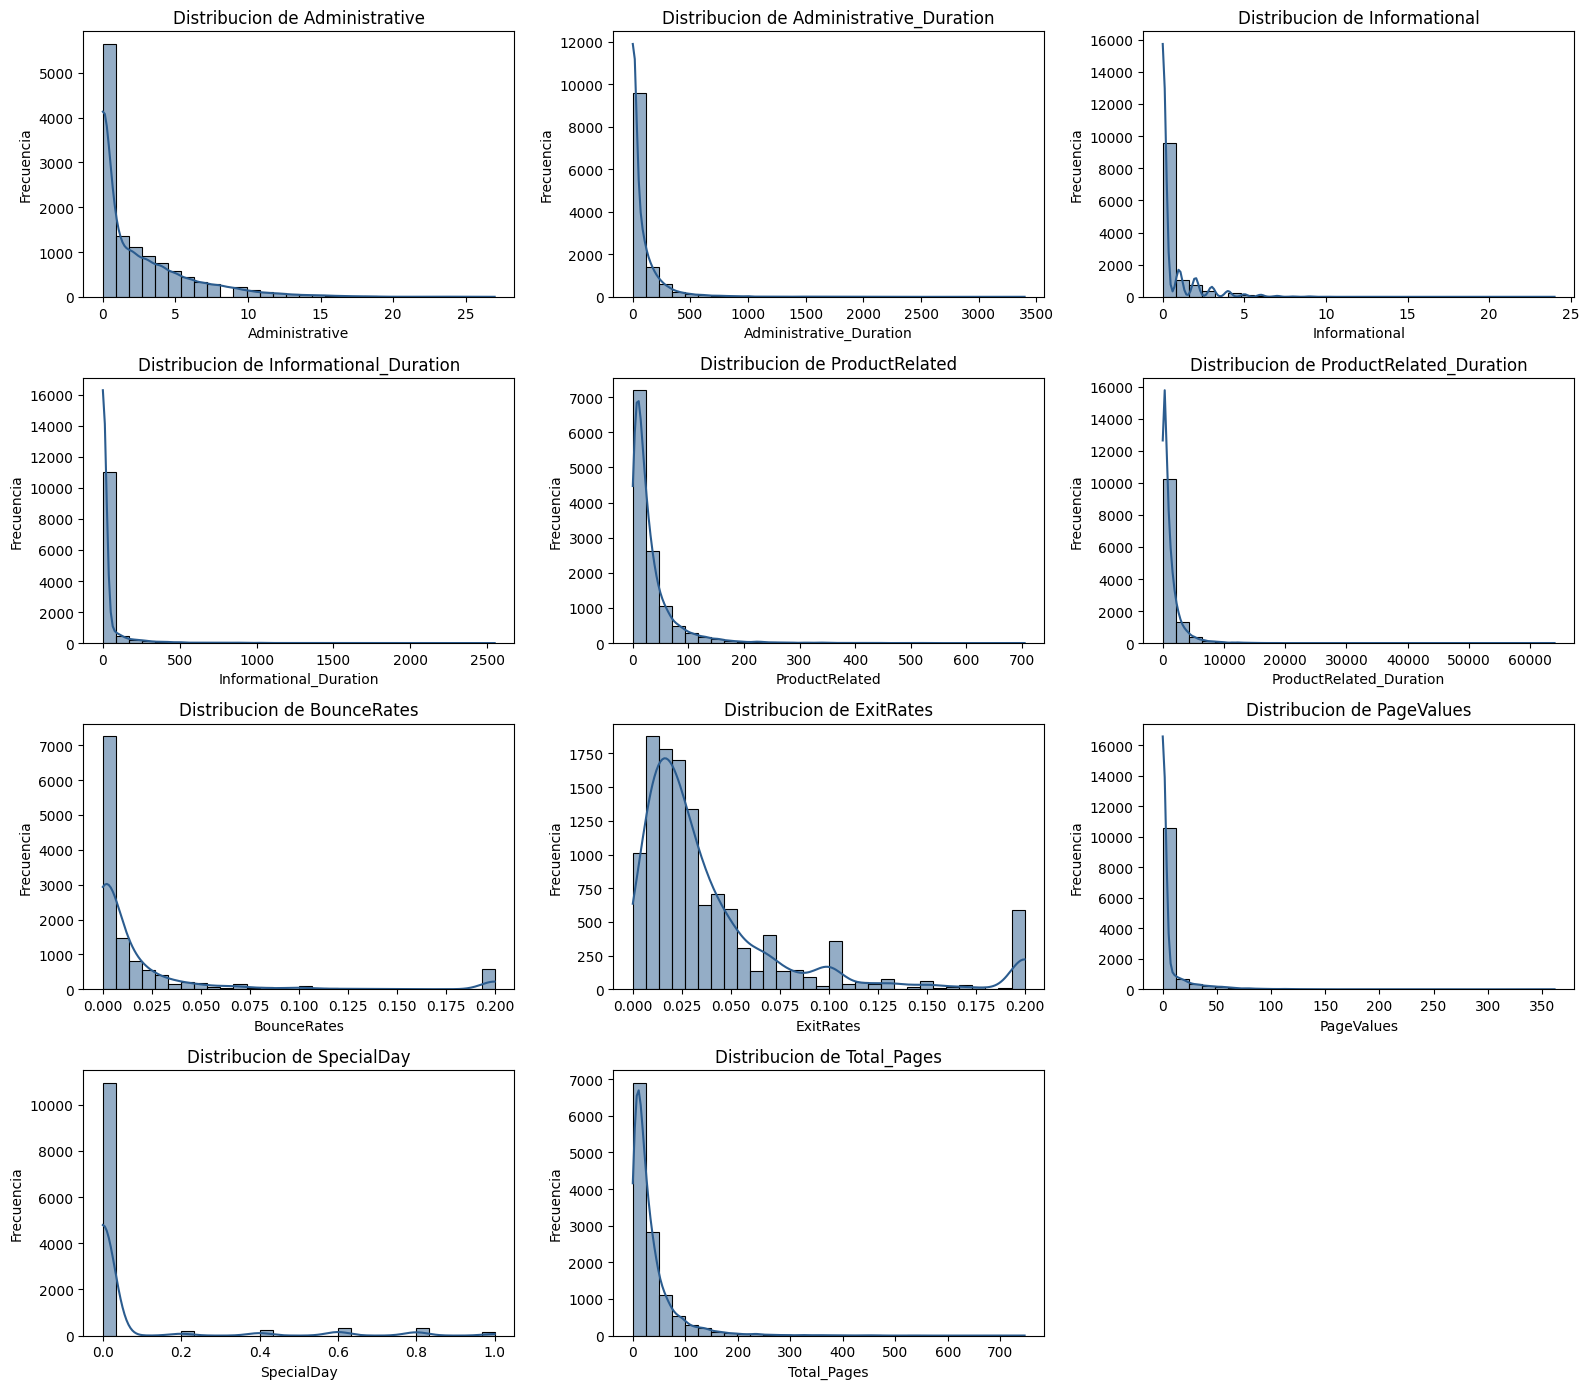

In [77]:
#GRAFICAR HISTOGRAMAS CON CURVA DE DENSIDAD
fig, axes = plt.subplots(4, 3, figsize=(16, 14))
axes = axes.flatten()

for i, v in enumerate(cols_num_eda):
    sns.histplot(df[v], kde=True, bins=30, ax=axes[i], color='#2b5c8f')
    axes[i].set_title(f'Distribucion de {v}')
    axes[i].set_xlabel(v)
    axes[i].set_ylabel('Frecuencia')

axes[-1].axis('off')
plt.tight_layout()
plt.show()

# NOTA 7:
- OBSERVAMOS NUESTRAS GRAFICAS DE HISTOGRAMAS CON SU RESPECTIVA CURVA
- PODEMOS OBSERVAR QUE TODAS LAS GRAFICAS DE CADA VARIABLE CUENTAN CON UNA CONCENTRACION HACIA LOS VALORES MINIMOS CON UNA COLA LARGA HACIA LA DERECHA, REFORZANDO LOS VALORES DE ASIMETRIA QUE PUDIMOS OBSERVAR ANTERIORMENTE, PUES ESTOS SE ENCONTRABAN EN UNA ASIMETRIA POSITIVA

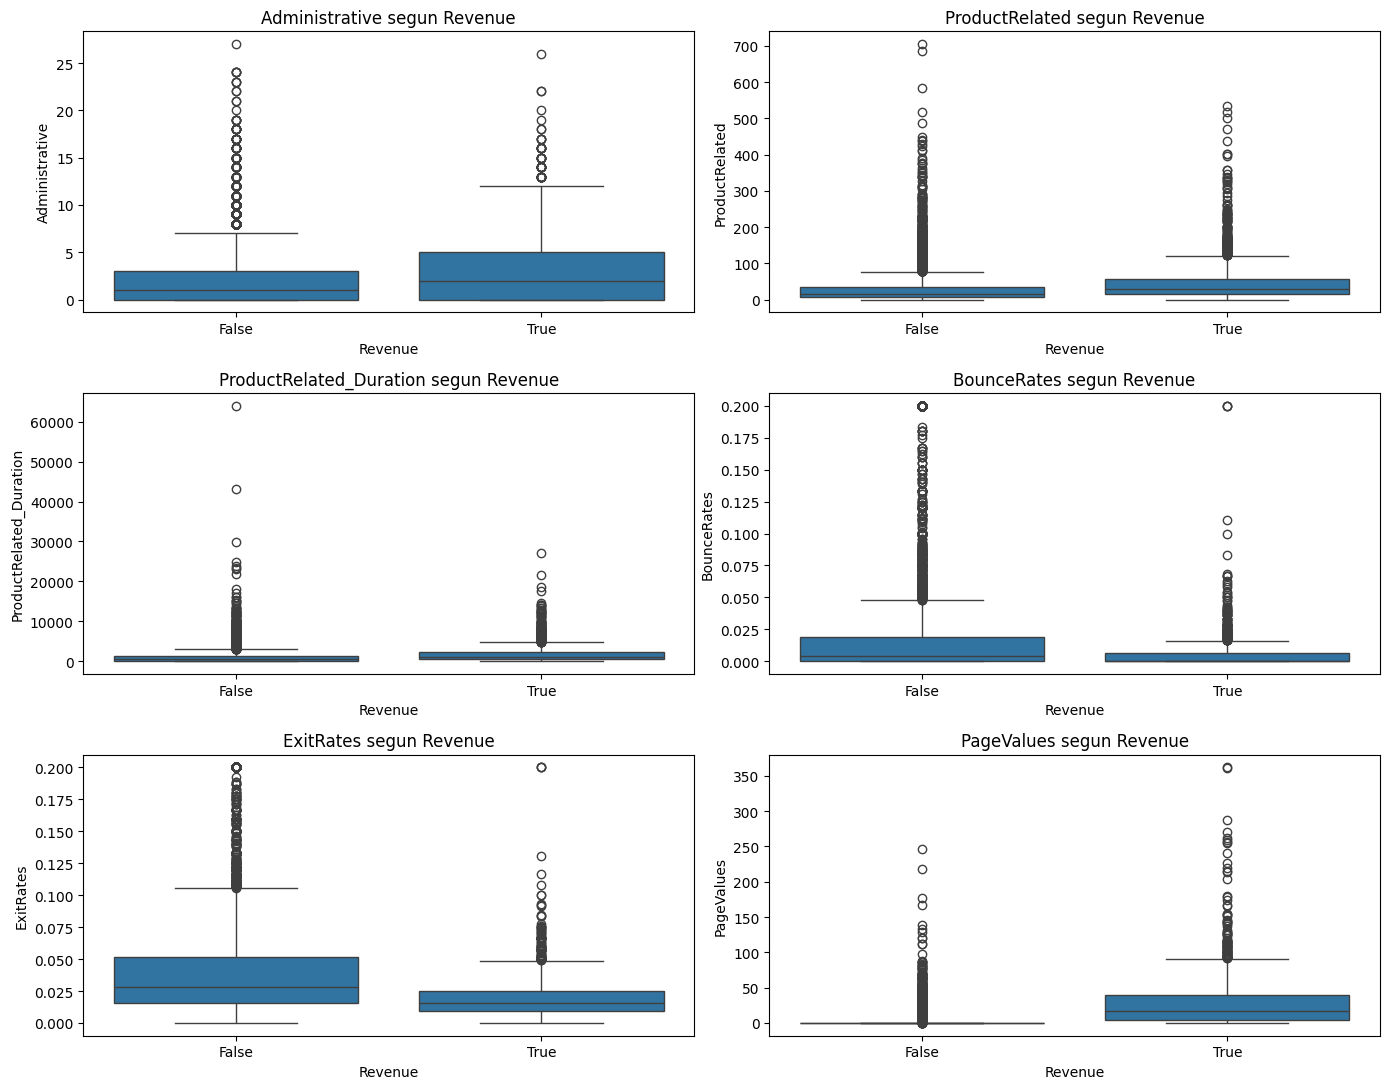

In [78]:
#DEFINIR VARIABLES PRINCIPALES PARA BOXPLOTS
vars_box = [
    'Administrative', 'ProductRelated',
    'ProductRelated_Duration', 'BounceRates',
    'ExitRates', 'PageValues'
]

#GRAFICAR BOXPLOTS DIVIDIDOS POR REVENUE
fig, axes = plt.subplots(3, 2, figsize=(14, 11))
axes = axes.flatten()

for i, v in enumerate(vars_box):
    sns.boxplot(data=df, x='Revenue', y=v, ax=axes[i])
    axes[i].set_title(f'{v} segun Revenue')

plt.tight_layout()
plt.show()

# NOTA 8:
- AQUI P0DEMOS OBSERVAR NUESTROS CUARTILES EN LAS GRAFICAS BOXPLOT
- PODEMOS OBSERVAR QUE TODAS LAS GRAFICAS CUENTAN CON VALORES ATIPICOS POR ENCIMA DEL IQR MAXIMO, TENIENDO AUSENCIA DE VALORES ATIPIMOS POR DEBAJO DE NUESTRO IQR
- LA CONCETRACION DE LOS VALORES SIGUE SIENDO EN VALORES MAS BAJOS, POR LO QUE SEGUIMOS REFORZANDO LA PARTE DE LA ASIMETRIA POSITIVA
- TODAS LAS GRAFICAS ESTAN DIVIDIDAS POR REVENUE (COMPRAS REALIZADAS)
- LOS COMPRADORES TIENEN REBOTES PEGADOS A 0.0 Y SALIDAS MUCHO MENORES
- PODEMOS VER QUE PAGEVALUES TIENE UNA MEDIANA DE 0.0 EN FALSE, MIENTRAS QUE EN TRUE CUENTA CON 16.76, POR LO QUE ES LA SEPARACION MAS GRANDE DE TODO EL DATASET

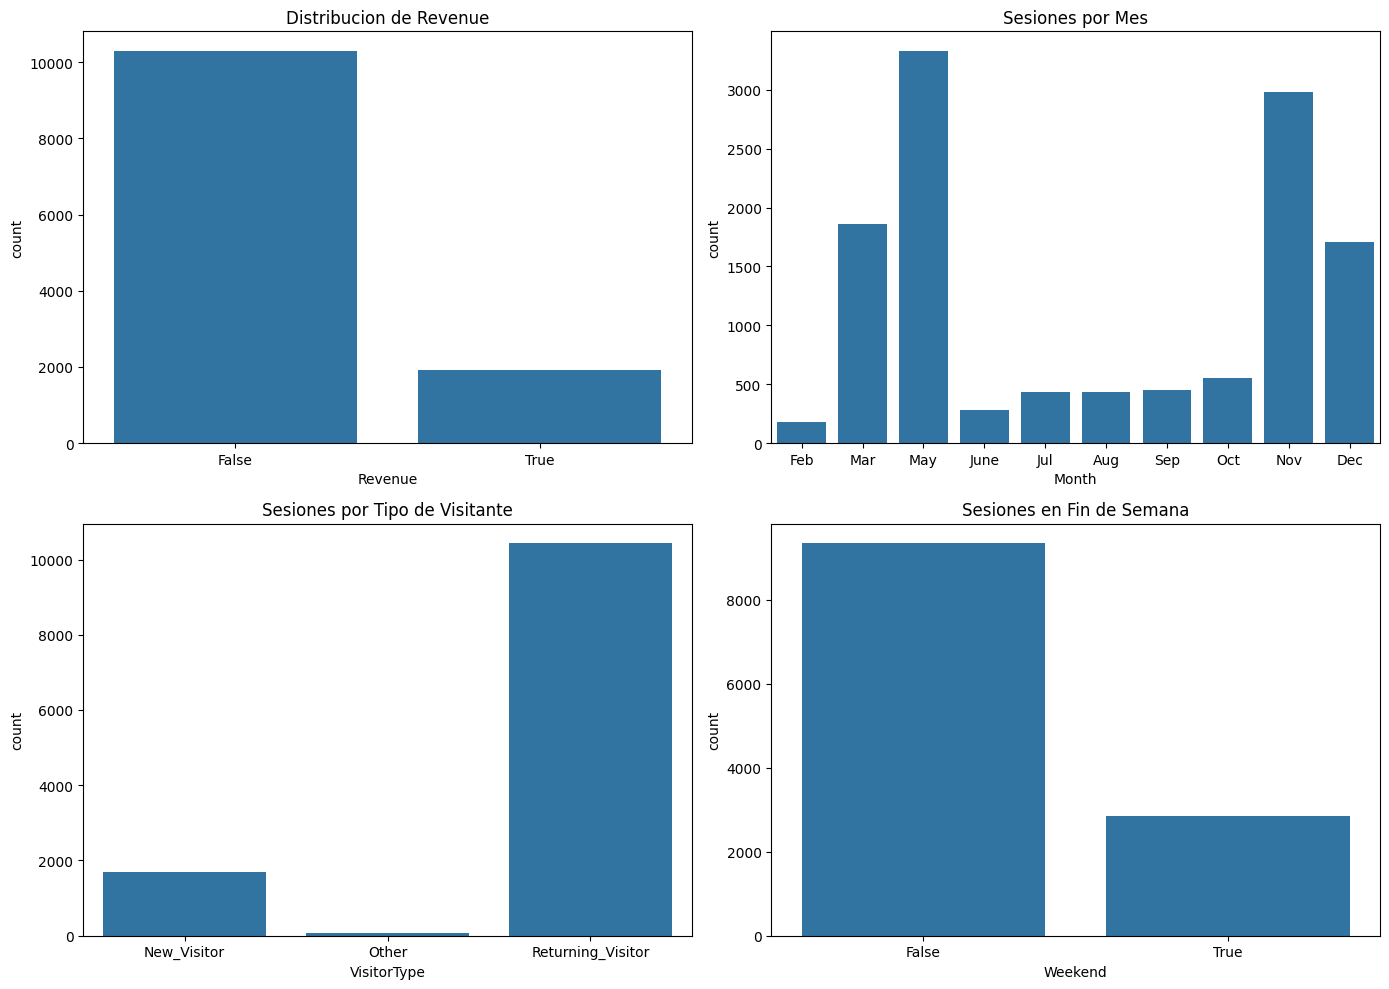

In [79]:
#ORDEN CRONOLOGICO DE MESES PRESENTES EN EL DATASET
orden_meses = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

#GRAFICAR CONTEOS DE VARIABLES CATEGORICAS PRINCIPALES
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=df, x='Revenue', ax=axes[0, 0])
axes[0, 0].set_title('Distribucion de Revenue')

sns.countplot(data=df, x='Month', order=orden_meses, ax=axes[0, 1])
axes[0, 1].set_title('Sesiones por Mes')

sns.countplot(data=df, x='VisitorType', ax=axes[1, 0])
axes[1, 0].set_title('Sesiones por Tipo de Visitante')

sns.countplot(data=df, x='Weekend', ax=axes[1, 1])
axes[1, 1].set_title('Sesiones en Fin de Semana')

plt.tight_layout()
plt.show()

# NOTA 9:
- PRESENTAMOS LAS GRAFICAS PARA NUESTRAS VARIABLES CATEGORICAS
- TENEMOS SOLAMENTE UNA VARIABLE CATEGORICA ORDINAL, QUE CORRESPONDE A LAS SESIONES POR MES. TODAS LAS DEMAS SON NOMINALES
- PARA EL MODELADO MONTH SE CODIFICA COMO NOMINAL PORQUE LA CONVERSION NO CRECE DE FORMA LINEAL MES CON MES
- COMO CONCLUSIONES PODEMOS OBSERVAR QUE HAY MENOS SESIONES EN FIN DE SEMANA
- LA MAYORIA DE SESIONES SON DE USUARIOS QUE REGRESAN Y EL MENOR NUMERO DE SESIONES PERTENECEN A OTRO TIPO DE VISITANTES
- LA MAYORIA DE LAS SESIONES NO TERMINAN EN UNA COMPRA REALIZADA
- WEEKEND Y REVENUE SON BINARIAS

Tasa de compra (%) por Mes:
 Month
Feb      1.66
Mar     10.32
May     10.96
June    10.18
Jul     15.28
Aug     17.55
Sep     19.20
Oct     20.95
Nov     25.49
Dec     12.66
Name: Revenue, dtype: float64

Tasa de compra (%) por VisitorType:
 VisitorType
New_Visitor          24.93
Other                19.75
Returning_Visitor    14.09
Name: Revenue, dtype: float64

Tasa de compra (%) por Visited_Admin:
 Visited_Admin
0     9.11
1    21.24
Name: Revenue, dtype: float64

Tasa de compra (%) por Visited_PageValues:
 Visited_PageValues
0     3.91
1    56.34
Name: Revenue, dtype: float64


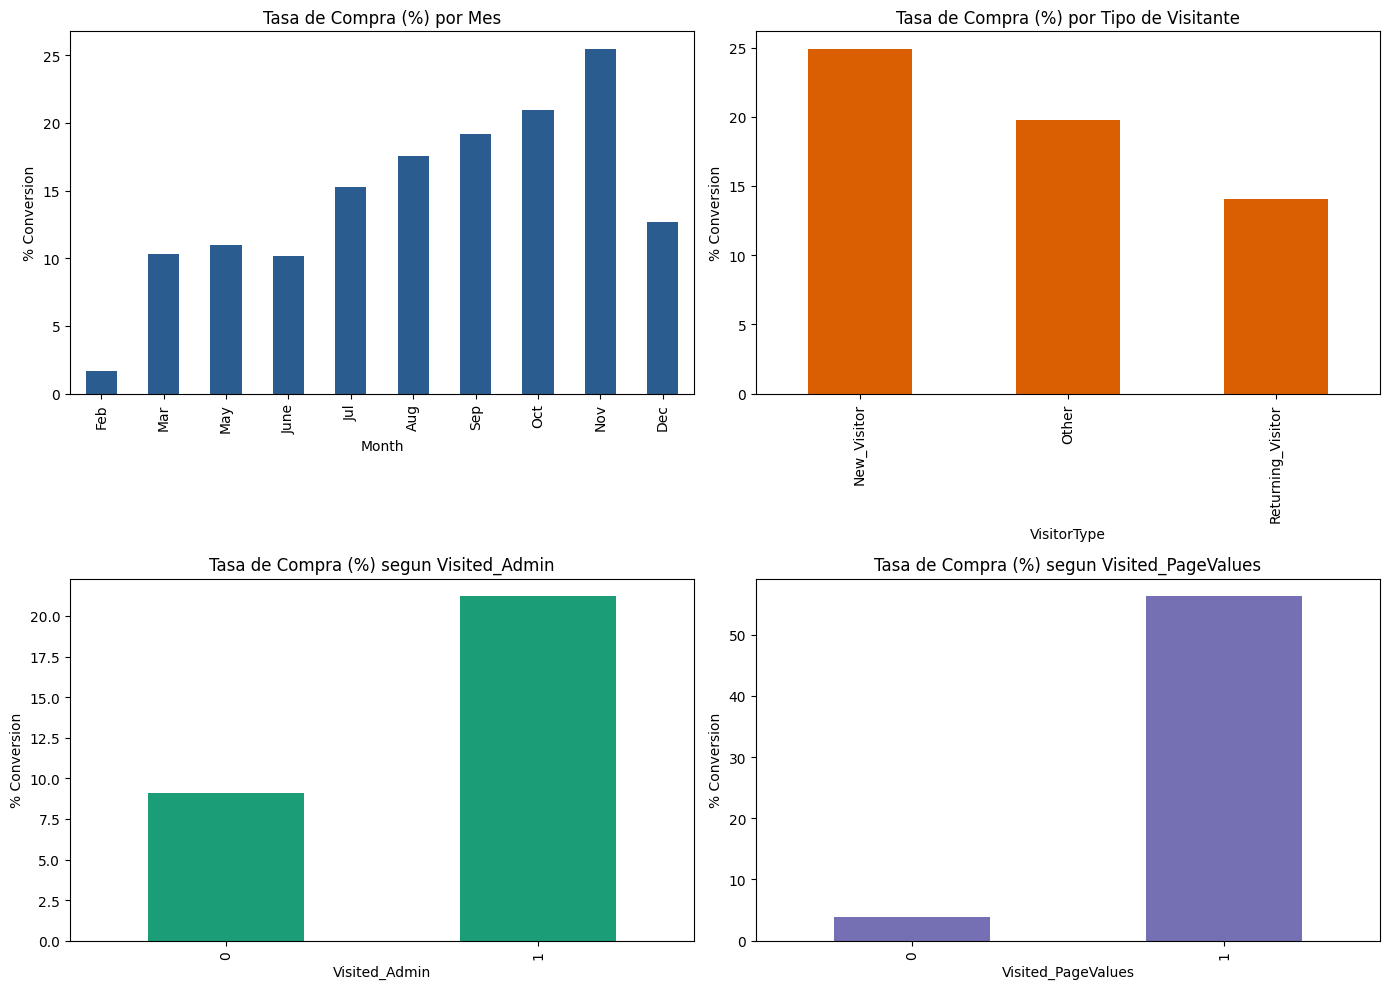

In [80]:
#CALCULAR TASAS DE CONVERSION POR CATEGORIA Y VARIABLES NUEVAS
conv_mes = df.groupby('Month', observed=False)['Revenue'].mean().reindex(orden_meses) * 100
conv_vis = df.groupby('VisitorType', observed=False)['Revenue'].mean() * 100
conv_admin = df.groupby('Visited_Admin')['Revenue'].mean() * 100
conv_pv = df.groupby('Visited_PageValues')['Revenue'].mean() * 100

print("Tasa de compra (%) por Mes:\n", conv_mes.round(2))
print("\nTasa de compra (%) por VisitorType:\n", conv_vis.round(2))
print("\nTasa de compra (%) por Visited_Admin:\n", conv_admin.round(2))
print("\nTasa de compra (%) por Visited_PageValues:\n", conv_pv.round(2))

#GRAFICAR TASAS DE CONVERSION
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

conv_mes.plot(kind='bar', ax=axes[0, 0], color='#2b5c8f')
axes[0, 0].set_title('Tasa de Compra (%) por Mes')
axes[0, 0].set_ylabel('% Conversion')

conv_vis.plot(kind='bar', ax=axes[0, 1], color='#d95f02')
axes[0, 1].set_title('Tasa de Compra (%) por Tipo de Visitante')
axes[0, 1].set_ylabel('% Conversion')

conv_admin.plot(kind='bar', ax=axes[1, 0], color='#1b9e77')
axes[1, 0].set_title('Tasa de Compra (%) segun Visited_Admin')
axes[1, 0].set_ylabel('% Conversion')

conv_pv.plot(kind='bar', ax=axes[1, 1], color='#7570b3')
axes[1, 1].set_title('Tasa de Compra (%) segun Visited_PageValues')
axes[1, 1].set_ylabel('% Conversion')

plt.tight_layout()
plt.show()

# NOTA 10:
- EN ESTAS GRAFICAS DE BARRAS PODEMOS OBSERVAR LA TASA DE COMPRA POR CADA VARIABLE CATEGORICA (O BINARIA), REFORZANDO NUESTRO PUNTO ANTERIOR
- OBSERVAMOS QUE EL MES QUE TIENE MEJOR TASA DE COMPRA ES NOVIEMBRE, MIENTRAS QUE EL QUE MENOR TASA DE CONVERSION TIENE ES FEBRERO. NO SE ENCUENTRAN REGISTROS DE ENERO Y ABRIL EN EL DATASET
- LOS NUEVOS VISITANTES TIENEN MEJOR TASA DE COMPRA CON RESPECTO A LOS DEMAS TIPOS DE USUARIO
- LAS SESIONES QUE VISITAN UNA PAGINA ADMINISTRATIVA TIENEN MEJOR TASA DE COMPRA QUE LAS QUE NO VISITAN UNA PAGINA ADMINISTRATIVA. LO MISMO OCURRE CON LA TASA DE COMPRA DE LAS VISITAS A PAGINAS CON VALOR

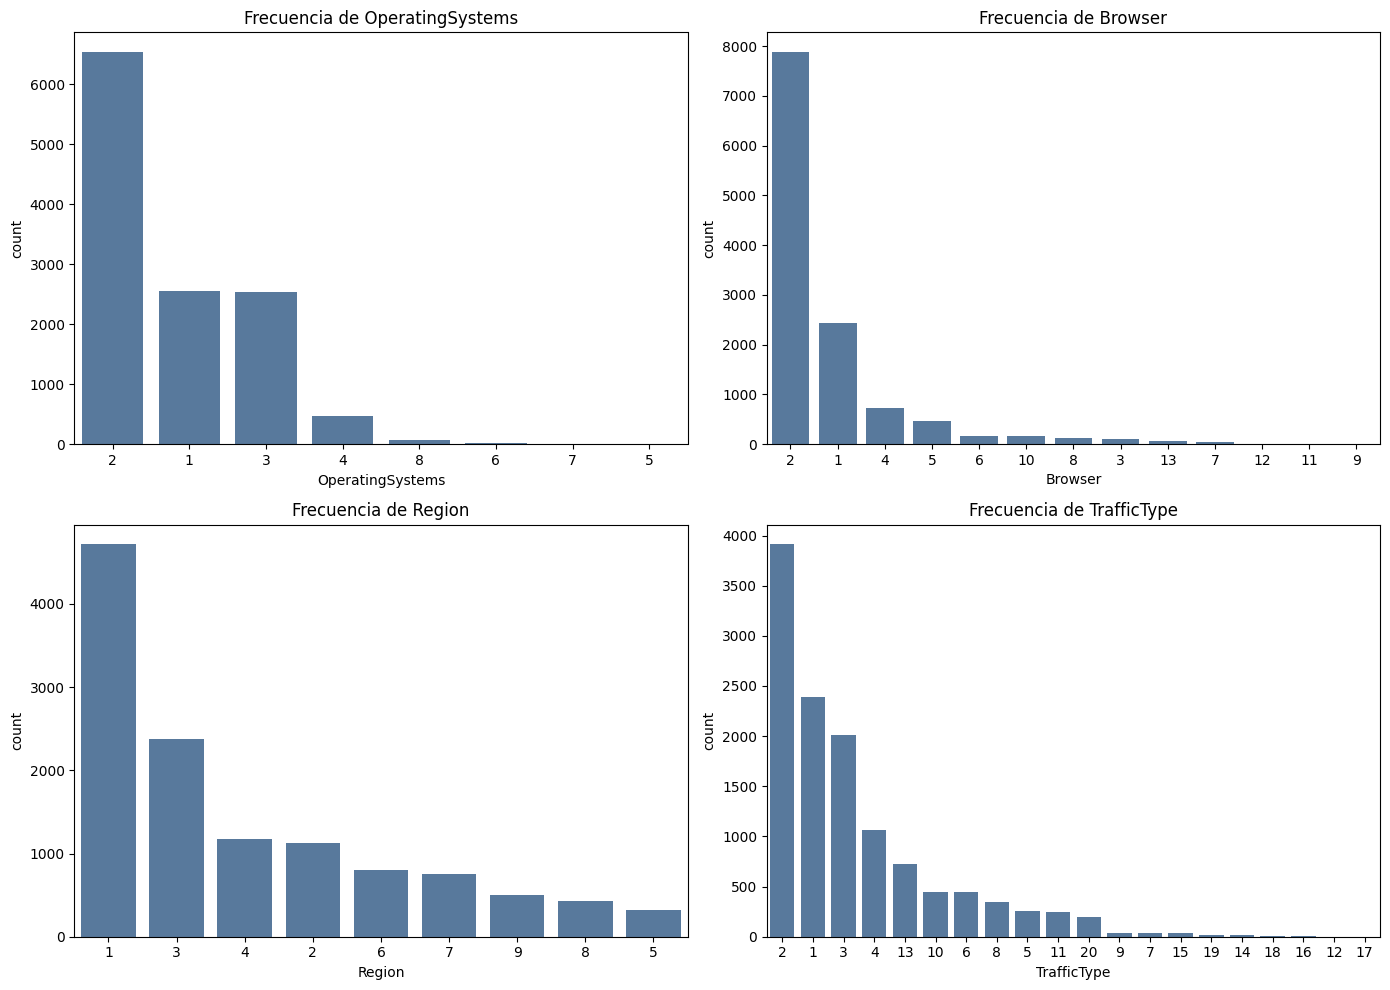

In [81]:
#GRAFICAR FRECUENCIAS DE VARIABLES NOMINALES CON CODIGO NUMERICO
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flatten(), variables_nominales_codigo):
    orden = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=orden, ax=ax, color='#4D79A7')
    ax.set_title(f'Frecuencia de {col}')

plt.tight_layout()
plt.show()

# NOTA 11:
- ESTAS GRAFICAS REPRESENTAN LAS FRECUENCIAS DE LAS VARIABLES NOMINALES CON ENTEROS
- OBSERVAMOS QUE EL SISTEMA OPERATIVO NUMERO 2 ES EL MAS UTILIZADO POR LOS USUARIOS, MIENTRAS QUE EL NUMERO 5 ES EL QUE MENOR FRECUENCIA TIENE
- LO MISMO OCURRE CON LOS NAVEGADORES, EL 2 ES EL DE MAYOR FRECUENCIA CON RESPECTO AL 9 CON LA MENOR FRECUENCIA
- LA REGION 1 ES LA QUE MAYOR FRECUENCIA TIENE, MIENTRAS QUE LAS REGION 5 ES LA QUE MENOS CUENTA
- EN EL TIPO DE TRAFICO EL NUMERO 2 ES EL DE MAYOR FRECUENCIA MIENTRAS QUE EL 12 Y 17 CUENTA CON PRACTICAMENTE NULA

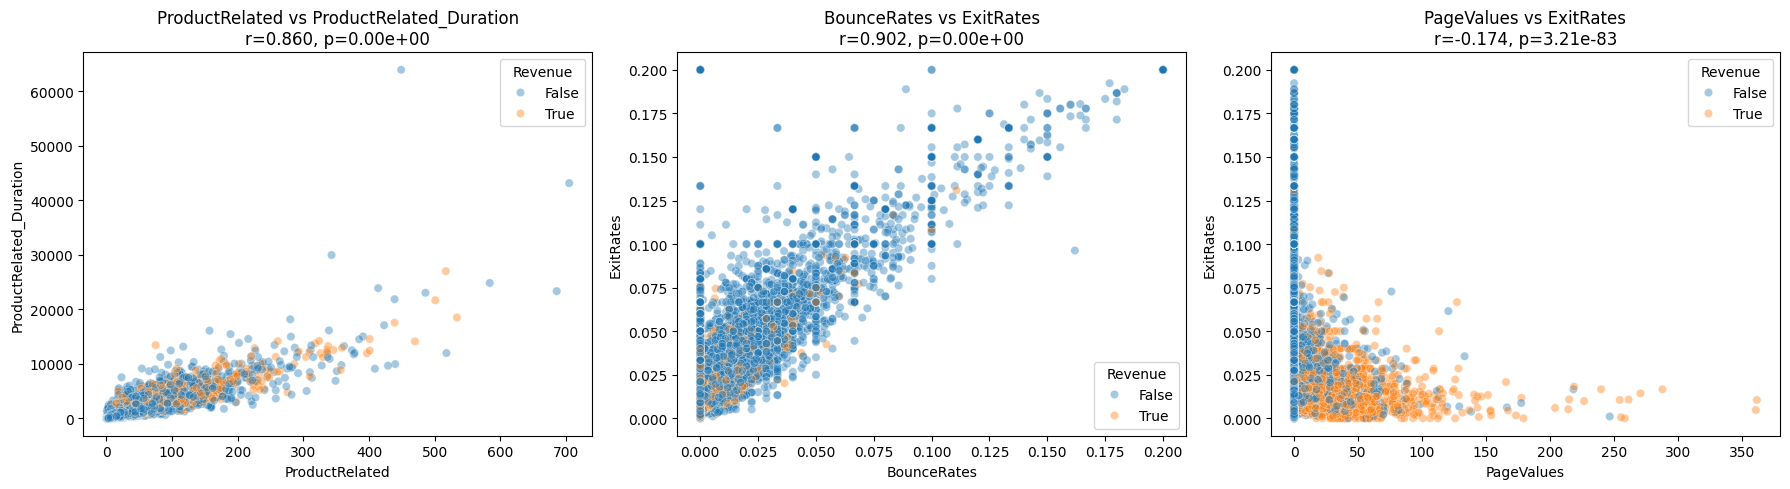

In [82]:
#DEFINIR PARES DE VARIABLES PARA DISPERSION
pares_disp = [
    ('ProductRelated', 'ProductRelated_Duration'),
    ('BounceRates', 'ExitRates'),
    ('PageValues', 'ExitRates'),
]

#GRAFICAR DISPERSION CON COEFICIENTE R Y VALOR P
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (x_col, y_col) in enumerate(pares_disp):
    r, p_val = pearsonr(df[x_col], df[y_col])
    sns.scatterplot(data=df, x=x_col, y=y_col, hue='Revenue', alpha=0.4, ax=axes[i])
    axes[i].set_title(f'{x_col} vs {y_col}\nr={r:.3f}, p={p_val:.2e}')

plt.tight_layout()
plt.show()

# NOTA 12:
- EN ESTAS GRAFICAS NOTAMOS COSAS INTERESANTES, PODEMOS VER QUE LA RELACION DE PRODUCTRELATES Y PRODUCTRELATED_DURATION TIENE UNA ALTA CORRELACION POSTIVA, LO MISMO PASA CON BOUNCERATES Y EXITRATES
- PAGEVALUE Y EXITRATE CUENTAN CON UNA CORRELACION BASTANTE BAJA
- TODAS CUENTAN CON UN P-VALUE CERCANO A CERO, POR LO QUE TENEMOS CERTEZA DE QUE ESTAS RELACIONES SON REALES Y TIENEN VALIDEZ

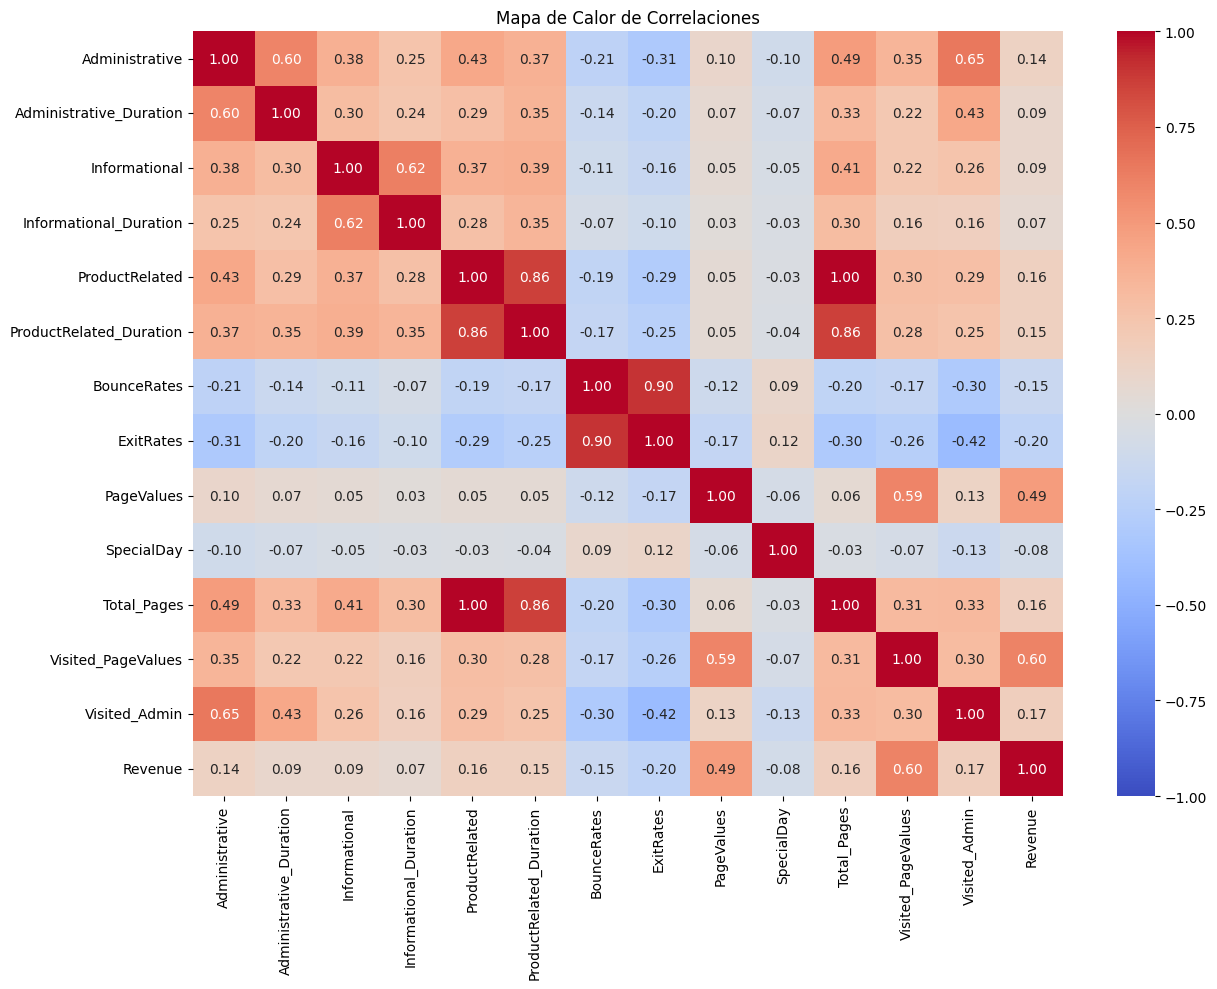

In [83]:
#CALCULAR MATRIZ DE CORRELACION LINEAL
cols_corr = variables_numericas + nuevas_variables + ['Revenue']
df_corr = df[cols_corr].copy()
df_corr['Revenue'] = df_corr['Revenue'].astype(int)
matriz_corr = df_corr.corr()

#GRAFICAR MAPA DE CALOR
plt.figure(figsize=(13, 10))
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Mapa de Calor de Correlaciones')
plt.tight_layout()
plt.show()

# NOTA 13:
- EN NUESTRA MATRIZ DE CORRELACION ENCONTRAMOS DIVERSAS CONCLUSIONES
- EN PRIMERA REFORZAMOS LO VISTO EN LAS GRAFICAS ANTERIORES, DONDE PRODUCTRELATED Y PRODUCTRELATED_DURATION CUENTAN CON UNA ALTA CORRELACION AL IGUAL QUE EXITRATES Y BOUNCERATES
- LA CORRELACION POSITICA MAS ALTA QUE PODEMOS OBSERVAR ES ENTRE PRODUCTRELATED Y TOTAL_PAGES. ESTO SE DEBE A QUE TOTAL_PAGES ESTA CONFORMADO POR EL TOTAL DE PAGINAS, POR LO QUE ES NORMAL YA QUE TODAS TIENEN RELACION CON LAS PAGINAS DE PRODUCTOS, PERO DEBEMOS DE TENER CUIDADO PARA EVITAR LA MULTICOLINEALIDAD
- LAS RELACIONES DE REVENUE CON VISITED PAGEVALUE Y PAGEVALUE CUENTAN CON CORRELACION POSITIVA MODERADAMENTE ALTA, DEL 0.60 Y 0.49 RESPECTIVAMENTE. SON LOS PRINCIPALES PREDICTORES PARA LA CLASIFICACION
- OTROS CASOS IGUALES AL ANTERIOR SERIAN ADMINISTRATIVE JUNTO CON ADMINISTRATIVE_DURATION E INFORMATIONAL CON INFORMATIONAL_DURATION
- TODAS LAS DEMAS RELACIONES MUESTRAN UNA CORRELACION TENDIENDO A BAJA, POR LO QUE NOS SIRVEN PARA EL PROCESAMIENTO DE LOS MODELOS

In [84]:
#EXPORTAR DATASET LIMPIO PARA SINCRONIZAR CON EL EQUIPO
df.to_csv('online_shoppers_clean.csv', index=False)
print("Archivo guardado: online_shoppers_clean.csv", df.shape)

#APLICAR ONE HOT ENCODING A VARIABLES NOMINALES
cols_ohe = ['Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
df_modelo = pd.get_dummies(df, columns=cols_ohe, drop_first=True, dtype=int)
df_modelo['Weekend'] = df_modelo['Weekend'].astype(int)
df_modelo['Revenue'] = df_modelo['Revenue'].astype(int)

#SEPARAR VARIABLES PREDICTORAS Y OBJETIVO
X = df_modelo.drop(columns=['Revenue'])
y = df_modelo['Revenue']

#DIVIDIR EN ENTRENAMIENTO Y PRUEBA CON ESTRATIFICACION
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

#ESTANDARIZAR VARIABLES NUMERICAS SIN FUGA DE DATOS
cols_escalar = variables_numericas + ['Total_Pages']
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[cols_escalar] = scaler.fit_transform(X_train[cols_escalar])
X_test_scaled[cols_escalar] = scaler.transform(X_test[cols_escalar])

#VERIFICAR DIMENSIONES Y PROPORCIONES FINALES
print("Forma de df_modelo:", df_modelo.shape)
print("X_train:", X_train_scaled.shape, "| X_test:", X_test_scaled.shape)
print("Proporcion Revenue=True en train:", round(y_train.mean() * 100, 2), "%")
print("Proporcion Revenue=True en test:", round(y_test.mean() * 100, 2), "%")
display(X_train_scaled[cols_escalar].describe().T[['mean', 'std', 'min', 'max']].round(3))

Archivo guardado: online_shoppers_clean.csv (12205, 21)
Forma de df_modelo: (12205, 72)
X_train: (9764, 71) | X_test: (2441, 71)
Proporcion Revenue=True en train: 15.63 %
Proporcion Revenue=True en test: 15.65 %


,mean,std,min,max
Administrative,-0.0,1.0,-0.699,7.362
Administrative_Duration,-0.0,1.0,-0.458,18.477
Informational,-0.0,1.0,-0.398,18.313
Informational_Duration,-0.0,1.0,-0.243,17.483
ProductRelated,0.0,1.0,-0.716,15.015
ProductRelated_Duration,-0.0,1.0,-0.627,32.584
BounceRates,-0.0,1.0,-0.449,3.973
ExitRates,0.0,1.0,-0.899,3.436
PageValues,0.0,1.0,-0.315,18.867
SpecialDay,0.0,1.0,-0.312,4.689


# NOTA 14:
- POR ULTIMO PARA TERMINAR CON LA PARTE DE PREPROCESAMIENTO Y ANALISIS EXPLORATORIO DE DATOS VAMOS A EXPORTAR EL DATASET LIMPIO
- EL DATASET QUEDA CON 12 205 FILAS Y 21 COLUMNAS POR LAS TRES VARIABLES NUEVAS
- APLICAMOS EL ONE HOT ENCODING A VARIABLES NOMINALES, ESTO PARA EL PROCESAMIENTO DE LOS MODELOS QUE REQUIEREN ENTRADAS NUMERICAS. USA DROP FIRTS PARA EVITAR MULTICOLINEALIDAD
- EL DATASET QUEDARIA EN 72 COLUMNAS (71 + REVENUE)
- SEPARAMOS NUESTRAS VARIABLE OBJETIVO DE LAS VARIABLES DE PREDICCION Y ESTRATIFICAMOS
- NOS QUEDAN 9764 REGISTROS PARA EL ENTRENAMIENTO CON 2441 DE PRUEBA. ESTO MANTIENE INTACTA LA PROPORCION DE COMPRA
- ESTANDARIZAMOS LAS VARIABLES NUMERICAS PARA SIN FUGA DE DATOS  
- DAMOS DIMENSIONES Y PROPORCIONES FINALES